In [1]:
SMOKE_TEST = False
RUN_MODE = "new"
ALLOW_OVERWRITE = False
RUN_CPU_SMOKE_CHECK = True
SAVE_EPOCH_PROGRESSION = True

assert isinstance(SMOKE_TEST, bool)
assert RUN_MODE in {"new", "resume", "overwrite"}, RUN_MODE
if RUN_MODE == "overwrite" and not ALLOW_OVERWRITE:
    raise PermissionError('RUN_MODE="overwrite" requires ALLOW_OVERWRITE=True (explicit authorization).')
print(f"SMOKE_TEST={SMOKE_TEST} | RUN_MODE={RUN_MODE} | ALLOW_OVERWRITE={ALLOW_OVERWRITE}")

SMOKE_TEST=False | RUN_MODE=new | ALLOW_OVERWRITE=False


In [2]:
import os, sys, subprocess, importlib, importlib.util
from importlib import metadata


def detect_colab() -> bool:
    try:
        import google.colab
        return True
    except ImportError:
        return False


IN_COLAB = detect_colab()

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    if not os.path.isdir("/content/drive/MyDrive"):
        raise RuntimeError("Google Drive did not mount correctly: /content/drive/MyDrive is missing.")
    OUTPUT_ROOT = "/content/drive/MyDrive/generative-model-comparison/06_ddpm"
    DATA_ROOT = "/content/data"
else:
    OUTPUT_ROOT = os.path.abspath(os.environ.get("DDPM_OUTPUT_ROOT", "./generative-model-comparison/06_ddpm"))
    DATA_ROOT = os.path.abspath(os.environ.get("DDPM_DATA_ROOT", "./data"))

REQUIRED_PYTORCH_FID = "0.3.0"


def installed_version(dist_name):
    try:
        return metadata.version(dist_name)
    except metadata.PackageNotFoundError:
        return None


_fid_ver = installed_version("pytorch-fid")
if _fid_ver != REQUIRED_PYTORCH_FID:
    if "pytorch_fid" in sys.modules:
        raise RuntimeError(f"pytorch_fid {_fid_ver} is already imported; restart the runtime and re-run.")
    print(f"Installing pytorch-fid=={REQUIRED_PYTORCH_FID} (found: {_fid_ver}) with --no-deps ...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--no-deps",
                           f"pytorch-fid=={REQUIRED_PYTORCH_FID}"])
    importlib.invalidate_caches()
    _fid_ver = installed_version("pytorch-fid")
assert _fid_ver == REQUIRED_PYTORCH_FID, f"pytorch-fid version {_fid_ver} != {REQUIRED_PYTORCH_FID}"

for _mod in ["torch", "torchvision", "numpy", "scipy", "matplotlib", "pandas", "PIL"]:
    if importlib.util.find_spec(_mod) is None:
        raise ImportError(f"Required module '{_mod}' is not available in this runtime.")

print("IN_COLAB   :", IN_COLAB)
print("OUTPUT_ROOT:", OUTPUT_ROOT)
print("DATA_ROOT  :", DATA_ROOT)
print("pytorch-fid:", _fid_ver)

Mounted at /content/drive
Installing pytorch-fid==0.3.0 (found: None) with --no-deps ...
IN_COLAB   : True
OUTPUT_ROOT: /content/drive/MyDrive/generative-model-comparison/06_ddpm
DATA_ROOT  : /content/data
pytorch-fid: 0.3.0


In [3]:
import json, time, math, random, hashlib, shutil, platform, datetime, copy

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import torchvision
from torchvision.datasets import FashionMNIST
import matplotlib.pyplot as plt
import pandas as pd
import scipy
from scipy import linalg

import pytorch_fid
from pytorch_fid.inception import InceptionV3
from pytorch_fid.fid_score import calculate_frechet_distance as pytorch_fid_frechet_distance

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def environment_info() -> dict:
    info = {
        "python": sys.version.split()[0],
        "platform": platform.platform(),
        "torch": torch.__version__,
        "torchvision": torchvision.__version__,
        "numpy": np.__version__,
        "scipy": scipy.__version__,
        "pytorch_fid": getattr(pytorch_fid, "__version__", None),
        "cuda_available": torch.cuda.is_available(),
        "torch_cuda_version": torch.version.cuda,
        "cudnn_version": torch.backends.cudnn.version() if torch.cuda.is_available() else None,
        "cudnn_deterministic": torch.backends.cudnn.deterministic,
        "cudnn_benchmark": torch.backends.cudnn.benchmark,
        "device": str(DEVICE),
        "in_colab": IN_COLAB,
    }
    if torch.cuda.is_available():
        props = torch.cuda.get_device_properties(0)
        info.update({
            "gpu_name": torch.cuda.get_device_name(0),
            "gpu_count": torch.cuda.device_count(),
            "gpu_total_memory_gb": round(props.total_memory / 1024**3, 2),
            "gpu_compute_capability": f"{props.major}.{props.minor}",
        })
    return info


def _tmp_path(path):
    d, b = os.path.split(path)
    return os.path.join(d, f".{b}.tmp-{os.getpid()}")


def atomic_torch_save(obj, path):
    tmp = _tmp_path(path)
    torch.save(obj, tmp)
    os.replace(tmp, path)


def _json_default(o):
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, (np.ndarray, torch.Tensor)):
        return o.tolist()
    if isinstance(o, (set, tuple)):
        return list(o)
    raise TypeError(f"Not JSON serializable: {type(o)}")


def strict_json_dumps(obj) -> str:
    return json.dumps(obj, indent=2, allow_nan=False, default=_json_default)


def atomic_json_save(obj, path):
    text = strict_json_dumps(obj)
    tmp = _tmp_path(path)
    with open(tmp, "w", encoding="utf-8") as f:
        f.write(text)
    os.replace(tmp, path)


def _reject_constant(c):
    raise ValueError(f"Non-strict JSON constant found: {c}")


def strict_json_load(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f, parse_constant=_reject_constant)


def atomic_csv_save(df: pd.DataFrame, path):
    tmp = _tmp_path(path)
    df.to_csv(tmp, index=False)
    os.replace(tmp, path)


def atomic_npz_save(path, **arrays):
    tmp = _tmp_path(path)
    with open(tmp, "wb") as f:
        np.savez(f, **arrays)
    os.replace(tmp, path)


def atomic_savefig(fig, path, dpi=200):
    tmp = _tmp_path(path)
    fig.savefig(tmp, dpi=dpi, bbox_inches="tight", format="png", facecolor="white")
    os.replace(tmp, path)


def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            b = f.read(chunk)
            if not b:
                break
            h.update(b)
    return h.hexdigest()


def cuda_sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


ENV_INFO = environment_info()
for k, v in ENV_INFO.items():
    print(f"{k:24s}: {v}")
if DEVICE.type != "cuda" and not SMOKE_TEST:
    print("\nWARNING: no GPU detected. The full run (30 epochs, T=1000, 7,000-sample FID) is impractically slow on CPU. "
          "In Colab: Runtime > Change runtime type > GPU.")

python                  : 3.13.16
platform                : Linux-6.6.159+-x86_64-with-glibc2.39
torch                   : 2.14.1+cu130
torchvision             : 0.29.1+cu130
numpy                   : 2.4.6
scipy                   : 1.16.3
pytorch_fid             : 0.3.0
cuda_available          : True
torch_cuda_version      : 13.0
cudnn_version           : 92800
cudnn_deterministic     : True
cudnn_benchmark         : False
device                  : cuda
in_colab                : True
gpu_name                : Tesla T4
gpu_count               : 1
gpu_total_memory_gb     : 14.56
gpu_compute_capability  : 7.5


In [4]:
FULL_CONFIG = dict(
    model_id="06_ddpm",
    model_name="Denoising Diffusion Probabilistic Model (DDPM)",
    seed=42,

    split_seed=42, n_train_per_class=5600, n_val_per_class=700, n_test_per_class=700,

    T=1000, beta_schedule="linear", beta_start=1e-4, beta_end=0.02,
    prediction_target="epsilon", loss="epsilon-MSE",
    clip_x0_in_sampling=True, reverse_variance="posterior (beta_tilde_t)",

    in_channels=1, base_channels=32, channel_mult=[1, 2, 4], num_res_blocks=2,
    time_emb_dim=128, groupnorm_groups=8, dropout=0.1,

    optimizer="Adam", lr=2e-4, adam_betas=[0.9, 0.999], weight_decay=0.0,
    batch_size=128, epochs=30, grad_clip_norm=1.0,

    val_noise_seed=4242, val_batch_size=128,

    train_subset=None, val_subset=None,

    n_grid_samples=16, grid_seed=1001,
    trajectory_n_samples=8, trajectory_steps=[0, 200, 400, 600, 800, 1000], trajectory_seed=1002,
    progression_epochs=[1, 5, 10, 15, 20, 25, 30], progression_n_samples=8, progression_seed=1003,

    run_fid=True, fid_n_samples=7000, fid_sample_seed=2025, fid_gen_batch_size=64,
    fid_inception_batch_size=64, fid_dims=2048, save_fid_features=True,

    run_latency=True, latency_batch_size=64, latency_warmup=1, latency_repeats=3, latency_seed=3003,
)

SMOKE_OVERRIDES = dict(
    T=50, epochs=2, batch_size=64, train_subset=512, val_subset=256, val_batch_size=128,
    trajectory_steps=[0, 10, 20, 30, 40, 50], progression_epochs=[1, 2],
    run_fid=False, run_latency=False,
)

CONFIG = copy.deepcopy(FULL_CONFIG)
if SMOKE_TEST:
    CONFIG.update(SMOKE_OVERRIDES)
CONFIG["smoke_test"] = SMOKE_TEST


def assert_full_run_config(cfg):
    expected = dict(epochs=30, batch_size=128, T=1000, lr=2e-4, seed=42, grad_clip_norm=1.0,
                    beta_start=1e-4, beta_end=0.02, beta_schedule="linear", optimizer="Adam",
                    fid_n_samples=7000, fid_dims=2048, latency_batch_size=64, latency_warmup=1,
                    latency_repeats=3, run_fid=True, run_latency=True, train_subset=None, val_subset=None,
                    split_seed=42, n_train_per_class=5600, n_val_per_class=700, n_test_per_class=700,
                    base_channels=32, time_emb_dim=128, smoke_test=False, val_batch_size=128, fid_gen_batch_size=64, fid_inception_batch_size=64)
    bad = {k: (cfg.get(k), v) for k, v in expected.items() if cfg.get(k) != v}
    assert not bad, f"Full-run config deviates from the project protocol: {bad}"
    assert cfg["trajectory_steps"][0] == 0 and cfg["trajectory_steps"][-1] == cfg["T"]


if not SMOKE_TEST:
    assert_full_run_config(CONFIG)
assert all(0 <= s <= CONFIG["T"] for s in CONFIG["trajectory_steps"])
assert CONFIG["trajectory_steps"][-1] == CONFIG["T"]

print(("SMOKE TEST CONFIG (not for reporting)" if SMOKE_TEST else "FULL RUN CONFIG"))
for k, v in CONFIG.items():
    print(f"  {k:26s} = {v}")

FULL RUN CONFIG
  model_id                   = 06_ddpm
  model_name                 = Denoising Diffusion Probabilistic Model (DDPM)
  seed                       = 42
  split_seed                 = 42
  n_train_per_class          = 5600
  n_val_per_class            = 700
  n_test_per_class           = 700
  T                          = 1000
  beta_schedule              = linear
  beta_start                 = 0.0001
  beta_end                   = 0.02
  prediction_target          = epsilon
  loss                       = epsilon-MSE
  clip_x0_in_sampling        = True
  reverse_variance           = posterior (beta_tilde_t)
  in_channels                = 1
  base_channels              = 32
  channel_mult               = [1, 2, 4]
  num_res_blocks             = 2
  time_emb_dim               = 128
  groupnorm_groups           = 8
  dropout                    = 0.1
  optimizer                  = Adam
  lr                         = 0.0002
  adam_betas                 = [0.9, 0.999]
  weight_

In [5]:
class DiffusionSchedule:
    """Linear-beta DDPM schedule with all forward / posterior coefficients."""

    def __init__(self, T: int, beta_start: float, beta_end: float, device):
        self.T = int(T)
        betas = np.linspace(beta_start, beta_end, self.T, dtype=np.float64)
        alphas = 1.0 - betas
        alpha_bar = np.cumprod(alphas)
        alpha_bar_prev = np.append(1.0, alpha_bar[:-1])

        posterior_variance = betas * (1.0 - alpha_bar_prev) / (1.0 - alpha_bar)
        coef_x0 = betas * np.sqrt(alpha_bar_prev) / (1.0 - alpha_bar)
        coef_xt = (1.0 - alpha_bar_prev) * np.sqrt(alphas) / (1.0 - alpha_bar)
        sqrt_recip_ab = np.sqrt(1.0 / alpha_bar)
        sqrt_recipm1_ab = np.sqrt(1.0 / alpha_bar - 1.0)
        self.np = dict(betas=betas, alphas=alphas, alpha_bar=alpha_bar, alpha_bar_prev=alpha_bar_prev,
                       posterior_variance=posterior_variance, coef_x0=coef_x0, coef_xt=coef_xt,
                       sqrt_recip_ab=sqrt_recip_ab, sqrt_recipm1_ab=sqrt_recipm1_ab)

        def t32(a):
            return torch.tensor(a, dtype=torch.float32, device=device)

        self.betas = t32(betas)
        self.alpha_bar = t32(alpha_bar)
        self.sqrt_alpha_bar = t32(np.sqrt(alpha_bar))
        self.sqrt_one_minus_alpha_bar = t32(np.sqrt(1.0 - alpha_bar))
        self.f_coef_x0 = coef_x0.tolist()
        self.f_coef_xt = coef_xt.tolist()
        self.f_sqrt_recip_ab = sqrt_recip_ab.tolist()
        self.f_sqrt_recipm1_ab = sqrt_recipm1_ab.tolist()
        self.f_post_std = np.sqrt(posterior_variance).tolist()
        self.f_sqrt_recip_alpha = np.sqrt(1.0 / alphas).tolist()
        self.f_eps_coef = (betas / np.sqrt(1.0 - alpha_bar)).tolist()


def q_sample(sched: DiffusionSchedule, x0, t, noise):
    a = sched.sqrt_alpha_bar[t].view(-1, 1, 1, 1)
    s = sched.sqrt_one_minus_alpha_bar[t].view(-1, 1, 1, 1)
    return a * x0 + s * noise


def to_model_space(x_unit):
    return x_unit * 2.0 - 1.0


def to_unit(x_model):
    return ((x_model + 1.0) / 2.0).clamp(0.0, 1.0)

In [6]:
def timestep_embedding(t, dim, max_period=10000):
    half = dim // 2
    freqs = torch.exp(-math.log(max_period) * torch.arange(half, dtype=torch.float32, device=t.device) / half)
    args = t.float()[:, None] * freqs[None, :]
    emb = torch.cat([torch.sin(args), torch.cos(args)], dim=1)
    if dim % 2 == 1:
        emb = F.pad(emb, (0, 1))
    return emb


class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, temb_dim, groups, dropout):
        super().__init__()
        self.norm1 = nn.GroupNorm(groups, in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.temb_proj = nn.Linear(temb_dim, out_ch)
        self.norm2 = nn.GroupNorm(groups, out_ch)
        self.dropout = nn.Dropout(dropout)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, temb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.temb_proj(F.silu(temb))[:, :, None, None]
        h = self.conv2(self.dropout(F.silu(self.norm2(h))))
        return h + self.skip(x)


class Downsample(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.conv = nn.Conv2d(ch, ch, 3, stride=2, padding=1)

    def forward(self, x):
        return self.conv(x)


class Upsample(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.conv = nn.Conv2d(ch, ch, 3, padding=1)

    def forward(self, x):
        return self.conv(F.interpolate(x, scale_factor=2, mode="nearest"))


class UNet(nn.Module):
    def __init__(self, in_channels=1, base_channels=32, channel_mult=(1, 2, 4), num_res_blocks=2,
                 time_emb_dim=128, groupnorm_groups=8, dropout=0.1):
        super().__init__()
        self.time_emb_dim = time_emb_dim
        self.time_mlp = nn.Sequential(
            nn.Linear(time_emb_dim, time_emb_dim * 4), nn.SiLU(), nn.Linear(time_emb_dim * 4, time_emb_dim))
        chs = [base_channels * m for m in channel_mult]
        g, d, te = groupnorm_groups, dropout, time_emb_dim

        self.in_conv = nn.Conv2d(in_channels, chs[0], 3, padding=1)

        self.down_blocks, self.downsamples = nn.ModuleList(), nn.ModuleList()
        cur = chs[0]
        for i, ch in enumerate(chs):
            blocks = nn.ModuleList()
            for _ in range(num_res_blocks):
                blocks.append(ResBlock(cur, ch, te, g, d))
                cur = ch
            self.down_blocks.append(blocks)
            self.downsamples.append(Downsample(cur) if i < len(chs) - 1 else nn.Identity())

        self.mid = nn.ModuleList([ResBlock(cur, cur, te, g, d), ResBlock(cur, cur, te, g, d)])

        self.up_blocks, self.upsamples = nn.ModuleList(), nn.ModuleList()
        for i in reversed(range(len(chs))):
            ch = chs[i]
            blocks = nn.ModuleList([ResBlock(cur + ch, ch, te, g, d)])
            cur = ch
            for _ in range(num_res_blocks - 1):
                blocks.append(ResBlock(cur, ch, te, g, d))
            self.up_blocks.append(blocks)
            self.upsamples.append(Upsample(cur) if i > 0 else nn.Identity())

        self.out_norm = nn.GroupNorm(g, cur)
        self.out_conv = nn.Conv2d(cur, in_channels, 3, padding=1)
    def forward(self, x, t):
        temb = self.time_mlp(timestep_embedding(t, self.time_emb_dim))
        h = self.in_conv(x)
        skips = []
        for blocks, down in zip(self.down_blocks, self.downsamples):
            for b in blocks:
                h = b(h, temb)
            skips.append(h)
            h = down(h)
        for b in self.mid:
            h = b(h, temb)
        for blocks, up in zip(self.up_blocks, self.upsamples):
            h = torch.cat([h, skips.pop()], dim=1)
            for b in blocks:
                h = b(h, temb)
            h = up(h)
        return self.out_conv(F.silu(self.out_norm(h)))


def build_model(cfg):
    return UNet(in_channels=cfg["in_channels"], base_channels=cfg["base_channels"],
                channel_mult=tuple(cfg["channel_mult"]), num_res_blocks=cfg["num_res_blocks"],
                time_emb_dim=cfg["time_emb_dim"], groupnorm_groups=cfg["groupnorm_groups"],
                dropout=cfg["dropout"])


def count_trainable_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


@torch.no_grad()
def architecture_shape_table(m, device="cpu"):
    names = ["time_mlp", "in_conv"]
    names += [f"down_blocks.{i}.{j}" for i, bl in enumerate(m.down_blocks) for j in range(len(bl))]
    names += [f"downsamples.{i}" for i in range(len(m.downsamples))]
    names += [f"mid.{j}" for j in range(len(m.mid))]
    names += [f"up_blocks.{i}.{j}" for i, bl in enumerate(m.up_blocks) for j in range(len(bl))]
    names += [f"upsamples.{i}" for i in range(len(m.upsamples))]
    names += ["out_conv"]
    modules = dict(m.named_modules())
    rows, hooks = [], []
    for n in names:
        mod = modules[n]
        hooks.append(mod.register_forward_hook(
            lambda mod_, inp, out, n=n: rows.append(
                (n, type(mod_).__name__, tuple(out.shape), sum(p.numel() for p in mod_.parameters())))))
    was_training = m.training
    m.eval()
    try:
        out = m(torch.zeros(2, 1, 28, 28, device=device), torch.tensor([0, 999], device=device))
    finally:
        for h in hooks:
            h.remove()
        m.train(was_training)
    return rows, tuple(out.shape)


def print_architecture(m, device="cpu"):
    rows, out_shape = architecture_shape_table(m, device)
    print(f"{'module':22s} {'type':12s} {'output shape (batch=2)':26s} {'params':>10s}")
    for n, typ, shp, p in rows:
        print(f"{n:22s} {typ:12s} {str(shp):26s} {p:>10,d}")
    print(f"final output shape: {out_shape}  |  trainable parameters: {count_trainable_params(m):,}")
    return rows

In [7]:
@torch.no_grad()
def p_mean_std(model, sched, x_t, t_int, clip_x0=True):
    t = torch.full((x_t.shape[0],), t_int, device=x_t.device, dtype=torch.long)
    eps_hat = model(x_t, t)
    x0_hat = sched.f_sqrt_recip_ab[t_int] * x_t - sched.f_sqrt_recipm1_ab[t_int] * eps_hat
    if clip_x0:
        x0_hat = x0_hat.clamp(-1.0, 1.0)
    mean = sched.f_coef_x0[t_int] * x0_hat + sched.f_coef_xt[t_int] * x_t
    return mean, sched.f_post_std[t_int], eps_hat, x0_hat


@torch.no_grad()
def ddpm_sample(model, sched, n, device, generator, clip_x0=True, record_after_steps=None):
    was_training = model.training
    model.eval()
    record_set = set(record_after_steps or [])
    records = {}
    x = torch.randn((n, 1, 28, 28), generator=generator, device=device)
    if 0 in record_set:
        records[0] = x.detach().float().cpu()
    try:
        for i, t_int in enumerate(reversed(range(sched.T))):
            mean, std, _, _ = p_mean_std(model, sched, x, t_int, clip_x0)
            if t_int > 0:
                z = torch.randn(x.shape, generator=generator, device=device)
                x = mean + std * z
            else:
                x = mean
            if (i + 1) in record_set:
                records[i + 1] = x.detach().float().cpu()
    finally:
        model.train(was_training)
    return x, records

In [8]:
def run_cpu_smoke_check(cfg):
    cpu = torch.device("cpu")
    torch.manual_seed(0)
    m = build_model(cfg).to(cpu)

    t = torch.tensor([0, 1, 500, cfg["T"] - 1])
    e = timestep_embedding(t, cfg["time_emb_dim"])
    assert e.shape == (4, cfg["time_emb_dim"]) and torch.isfinite(e).all()
    assert not torch.allclose(e[0], e[1]), "distinct timesteps must give distinct embeddings"
    temb = m.time_mlp(e)
    assert temb.shape == (4, cfg["time_emb_dim"]) and torch.isfinite(temb).all()

    x = torch.rand(4, 1, 28, 28) * 2 - 1
    out = m(x, t)
    assert out.shape == x.shape, out.shape
    assert torch.isfinite(out).all()
    assert isinstance(m.out_conv, nn.Conv2d), "output head must be a plain conv (no tanh/sigmoid)"
    assert not any(isinstance(mod, (nn.Tanh, nn.Sigmoid)) for mod in m.modules())
    print_architecture(m, cpu)

    s = DiffusionSchedule(cfg["T"], cfg["beta_start"], cfg["beta_end"], cpu)
    b = s.np["betas"]
    assert len(b) == cfg["T"] and np.isclose(b[0], cfg["beta_start"]) and np.isclose(b[-1], cfg["beta_end"])
    assert np.all(np.diff(b) > 0) and np.all((s.np["alpha_bar"] > 0) & (s.np["alpha_bar"] < 1))
    pv = s.np["posterior_variance"]
    assert pv[0] == 0.0 and np.all(pv[1:] > 0) and np.all(pv <= b + 1e-12)
    print(f"alpha_bar[0]={s.np['alpha_bar'][0]:.6f}  alpha_bar[T-1]={s.np['alpha_bar'][-1]:.3e}")

    x0 = torch.rand(8, 1, 28, 28) * 2 - 1
    noise = torch.randn_like(x0)
    tt = torch.randint(0, cfg["T"], (8,))
    xt = q_sample(s, x0, tt, noise)
    ab = torch.tensor(s.np["alpha_bar"], dtype=torch.float64)[tt].view(-1, 1, 1, 1)
    ref = (ab.sqrt() * x0.double() + (1 - ab).sqrt() * noise.double()).float()
    assert torch.allclose(xt, ref, atol=1e-5), (xt - ref).abs().max()
    xt0 = q_sample(s, x0, torch.zeros(8, dtype=torch.long), noise)
    assert (xt0 - x0).std() < 0.02, "x_t at t=0 should be close to x_0 (noise std 0.01)"
    xtT = q_sample(s, x0, torch.full((8,), cfg["T"] - 1, dtype=torch.long), noise)
    if cfg["T"] >= 1000:
        corr = torch.corrcoef(torch.stack([xtT.flatten(), noise.flatten()]))[0, 1]
        assert corr > 0.99, f"x_t at t=T-1 should be almost pure noise (corr={corr:.4f})"

    m.eval()
    for t_int in [cfg["T"] - 1, cfg["T"] // 2, 1]:
        xt_ = torch.randn(3, 1, 28, 28)
        mean, std, eps_hat, _ = p_mean_std(m, s, xt_, t_int, clip_x0=False)
        mean_eps = s.f_sqrt_recip_alpha[t_int] * (xt_ - s.f_eps_coef[t_int] * eps_hat)
        assert torch.allclose(mean, mean_eps, atol=1e-4), (t_int, (mean - mean_eps).abs().max())
        assert std > 0

    s_small = DiffusionSchedule(20, cfg["beta_start"], cfg["beta_end"], cpu)
    g1 = torch.Generator(device="cpu").manual_seed(123)
    xs, rec = ddpm_sample(m, s_small, 4, cpu, g1, clip_x0=True, record_after_steps=[0, 10, 20])
    assert xs.shape == (4, 1, 28, 28) and torch.isfinite(xs).all()
    assert sorted(rec) == [0, 10, 20] and all(torch.isfinite(v).all() for v in rec.values())
    assert torch.equal(rec[20], xs.float().cpu())
    u = to_unit(xs)
    assert u.min() >= 0 and u.max() <= 1
    g2 = torch.Generator(device="cpu").manual_seed(123)
    xs2, _ = ddpm_sample(m, s_small, 4, cpu, g2, clip_x0=True)
    assert torch.equal(xs, xs2), "same seed must give identical samples"

    m.train()
    opt = torch.optim.Adam(m.parameters(), lr=cfg["lr"])
    loss = F.mse_loss(m(q_sample(s, x0, tt, noise), tt), noise)
    opt.zero_grad()
    loss.backward()
    assert torch.isfinite(loss)
    assert all(torch.isfinite(p.grad).all() for p in m.parameters() if p.grad is not None)
    gn = torch.nn.utils.clip_grad_norm_(m.parameters(), cfg["grad_clip_norm"])
    opt.step()
    assert all(torch.isfinite(p).all() for p in m.parameters())
    print(f"one-step loss={loss.item():.4f}  grad-norm(before clip)={gn.item():.3f}")
    print(f"trainable parameters: {count_trainable_params(m):,}")
    print("CPU SMOKE CHECK PASSED")
    return count_trainable_params(m)


if RUN_CPU_SMOKE_CHECK:
    _ = run_cpu_smoke_check(CONFIG)
else:
    print("CPU smoke check skipped (RUN_CPU_SMOKE_CHECK=False).")

module                 type         output shape (batch=2)         params
time_mlp               Sequential   (2, 128)                      131,712
in_conv                Conv2d       (2, 32, 28, 28)                   320
down_blocks.0.0        ResBlock     (2, 32, 28, 28)                22,752
down_blocks.0.1        ResBlock     (2, 32, 28, 28)                22,752
downsamples.0          Downsample   (2, 32, 14, 14)                 9,248
down_blocks.1.0        ResBlock     (2, 64, 14, 14)                65,984
down_blocks.1.1        ResBlock     (2, 64, 14, 14)                82,368
downsamples.1          Downsample   (2, 64, 7, 7)                  36,928
down_blocks.2.0        ResBlock     (2, 128, 7, 7)                246,656
down_blocks.2.1        ResBlock     (2, 128, 7, 7)                312,192
downsamples.2          Identity     (2, 128, 7, 7)                      0
mid.0                  ResBlock     (2, 128, 7, 7)                312,192
mid.1                  ResBlock     (2

In [9]:
RUN_DIR = os.path.join(OUTPUT_ROOT, "smoke_test") if SMOKE_TEST else OUTPUT_ROOT
SUBDIRS = ["checkpoints", "metrics", "samples", "figures"]
DIRS = {k: os.path.join(RUN_DIR, k) for k in SUBDIRS}

PATHS = dict(
    best_ckpt=os.path.join(DIRS["checkpoints"], "best_checkpoint.pt"),
    last_ckpt=os.path.join(DIRS["checkpoints"], "last_checkpoint.pt"),
    history_csv=os.path.join(DIRS["metrics"], "training_history.csv"),
    metrics_json=os.path.join(DIRS["metrics"], "metrics.json"),
    config_json=os.path.join(DIRS["metrics"], "resolved_config.json"),
    split_report=os.path.join(DIRS["metrics"], "split_report.json"),
    split_npz=os.path.join(DIRS["metrics"], "split_indices.npz"),
    fid_stats=os.path.join(DIRS["metrics"], "fid_stats.npz"),
    fid_features=os.path.join(DIRS["metrics"], "fid_features.npz"),
    fid_json=os.path.join(DIRS["metrics"], "fid.json"),
    latency_json=os.path.join(DIRS["metrics"], "latency.json"),
    samples_16=os.path.join(DIRS["samples"], "samples_16.pt"),
    trajectory=os.path.join(DIRS["samples"], "denoising_trajectory.pt"),
    generated_7000=os.path.join(DIRS["samples"], "generated_7000.pt"),
    progression_dir=os.path.join(DIRS["samples"], "progression"),
    fig_grid=os.path.join(DIRS["figures"], "samples_grid_4x4.png"),
    fig_trajectory=os.path.join(DIRS["figures"], "denoising_trajectory.png"),
    fig_loss=os.path.join(DIRS["figures"], "loss_curves.png"),
    fig_progression=os.path.join(DIRS["figures"], "sample_progression_by_epoch.png"),
)

assert os.path.basename(os.path.normpath(OUTPUT_ROOT)) == "06_ddpm", OUTPUT_ROOT


def existing_artifacts(run_dir):
    found = []
    for sd in SUBDIRS:
        d = os.path.join(run_dir, sd)
        if os.path.isdir(d):
            for root, _, files in os.walk(d):
                found += [os.path.join(root, f) for f in files]
    return found


_existing = existing_artifacts(RUN_DIR)
if RUN_MODE == "new":
    if _existing:
        raise FileExistsError(
            f"{len(_existing)} artifact(s) already exist in {RUN_DIR} (e.g. {_existing[0]}). "
            'Refusing to overwrite. Use RUN_MODE="resume", or RUN_MODE="overwrite" with ALLOW_OVERWRITE=True.')
elif RUN_MODE == "resume":
    if not os.path.isfile(PATHS["last_ckpt"]):
        raise FileNotFoundError(f'RUN_MODE="resume" but {PATHS["last_ckpt"]} does not exist.')
elif RUN_MODE == "overwrite":
    assert ALLOW_OVERWRITE
    if _existing:
        archive = os.path.join(RUN_DIR, "_archived_" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S"))
        os.makedirs(archive, exist_ok=False)
        for sd in SUBDIRS:
            if os.path.isdir(os.path.join(RUN_DIR, sd)):
                shutil.move(os.path.join(RUN_DIR, sd), os.path.join(archive, sd))
        print(f"Explicit overwrite authorized: moved previous artifacts to {archive}")

for d in list(DIRS.values()) + [PATHS["progression_dir"]]:
    os.makedirs(d, exist_ok=True)
print("RUN_DIR:", RUN_DIR)
for k, v in DIRS.items():
    print(f"  {k:12s} -> {v}")

RUN_DIR: /content/drive/MyDrive/generative-model-comparison/06_ddpm
  checkpoints  -> /content/drive/MyDrive/generative-model-comparison/06_ddpm/checkpoints
  metrics      -> /content/drive/MyDrive/generative-model-comparison/06_ddpm/metrics
  samples      -> /content/drive/MyDrive/generative-model-comparison/06_ddpm/samples
  figures      -> /content/drive/MyDrive/generative-model-comparison/06_ddpm/figures


In [10]:
MODEL01_SPLIT_REPORT_PATH = (
    "/content/drive/MyDrive/generative-model-comparison/01_vanilla_ae/results/split_report.json"
)
assert os.path.isfile(MODEL01_SPLIT_REPORT_PATH), (
    "Run Model 01 completely first; its split_report.json is the canonical split reference."
)
with open(MODEL01_SPLIT_REPORT_PATH) as f:
    EXPECTED_SPLIT_SHA256 = json.load(f)["index_sha256_int64"]

fashion_train = FashionMNIST(root=DATA_ROOT, train=True, download=True)
fashion_test = FashionMNIST(root=DATA_ROOT, train=False, download=True)
assert len(fashion_train) == 60000 and len(fashion_test) == 10000

images_u8 = np.concatenate([fashion_train.data.numpy(), fashion_test.data.numpy()], axis=0).astype(np.uint8)
assert images_u8.shape == (70000, 28, 28)

labels = np.concatenate([
    fashion_train.targets.numpy().astype(np.int64),
    fashion_test.targets.numpy().astype(np.int64),
])
rng = np.random.default_rng(42)
train_parts, val_parts, test_parts = [], [], []
for class_id in range(10):
    class_indices = np.flatnonzero(labels == class_id).copy()
    rng.shuffle(class_indices)
    train_parts.append(class_indices[:5600])
    val_parts.append(class_indices[5600:6300])
    test_parts.append(class_indices[6300:])
train_indices = np.concatenate(train_parts).astype(np.int64)
val_indices = np.concatenate(val_parts).astype(np.int64)
test_indices = np.concatenate(test_parts).astype(np.int64)
rng.shuffle(train_indices)
rng.shuffle(val_indices)
rng.shuffle(test_indices)


def index_sha256(idx: np.ndarray) -> str:
    return hashlib.sha256(np.ascontiguousarray(idx, dtype=np.int64).tobytes()).hexdigest()


SPLITS = {"train": train_indices, "validation": val_indices, "test": test_indices}
SPLIT_SHA256 = {k: index_sha256(v) for k, v in SPLITS.items()}

assert labels.shape == (70000,)
assert len(train_indices) == 56000 and len(val_indices) == 7000 and len(test_indices) == 7000
for name, idx, per in [("train", train_indices, 5600), ("validation", val_indices, 700), ("test", test_indices, 700)]:
    counts = np.bincount(labels[idx], minlength=10)
    assert np.all(counts == per), (name, counts)
    assert len(np.unique(idx)) == len(idx), f"duplicates in {name}"
assert len(np.intersect1d(train_indices, val_indices)) == 0
assert len(np.intersect1d(train_indices, test_indices)) == 0
assert len(np.intersect1d(val_indices, test_indices)) == 0
assert np.array_equal(np.sort(np.concatenate(list(SPLITS.values()))), np.arange(70000))

expected_check = "not_checked (EXPECTED_SPLIT_SHA256 values are None)"
for k, v in EXPECTED_SPLIT_SHA256.items():
    if v is not None:
        assert SPLIT_SHA256[k] == v, f"Split hash mismatch for {k}: {SPLIT_SHA256[k]} != expected {v}"
if any(v is not None for v in EXPECTED_SPLIT_SHA256.values()):
    expected_check = "passed for: " + ", ".join(k for k, v in EXPECTED_SPLIT_SHA256.items() if v is not None)

split_report = {
    "dataset": "Fashion-MNIST (28x28 grayscale, 10 classes)",
    "source": "torchvision.datasets.FashionMNIST train=True (60,000) + train=False (10,000), pooled to 70,000",
    "pooled_index_convention": "0..59999 = official train file, 60000..69999 = official test file",
    "official_test_partition_retained": False,
    "official_test_partition_note": ("The original official 10,000-image Fashion-MNIST test partition is NOT retained "
                                     "independently after pooling. All evaluation uses the project's stratified "
                                     "7,000-image test split."),
    "split_seed": 42,
    "algorithm": ("labels concatenated (train, test) as int64; rng=np.random.default_rng(42); for class_id in 0..9: "
                  "class_indices=flatnonzero(labels==class_id).copy(); rng.shuffle; [:5600]->train, "
                  "[5600:6300]->val, [6300:]->test; concatenate each as int64; then rng.shuffle(train), "
                  "rng.shuffle(val), rng.shuffle(test)"),
    "sizes": {k: int(len(v)) for k, v in SPLITS.items()},
    "per_class_counts": {k: np.bincount(labels[v], minlength=10).tolist() for k, v in SPLITS.items()},
    "origin_counts": {k: {"from_official_train": int((v < 60000).sum()), "from_official_test": int((v >= 60000).sum())}
                      for k, v in SPLITS.items()},
    "hash_method": "sha256(np.ascontiguousarray(indices, dtype=np.int64).tobytes())",
    "sha256": SPLIT_SHA256,
    "expected_sha256": EXPECTED_SPLIT_SHA256,
    "expected_hash_check": expected_check,
    "pooled_labels_sha256": hashlib.sha256(np.ascontiguousarray(labels, dtype=np.int64).tobytes()).hexdigest(),
    "first_10_indices": {k: v[:10].tolist() for k, v in SPLITS.items()},
    "disjoint_and_complete": True,
}

if RUN_MODE == "resume" and os.path.isfile(PATHS["split_report"]):
    _prev = strict_json_load(PATHS["split_report"])
    assert _prev["sha256"] == SPLIT_SHA256, "Split hashes differ from the previous run in this folder."
atomic_json_save(split_report, PATHS["split_report"])
atomic_npz_save(PATHS["split_npz"], train_indices=train_indices, val_indices=val_indices,
                test_indices=test_indices, labels=labels)

print("Split sizes:", split_report["sizes"])
print("Origin counts:", split_report["origin_counts"])
for k, v in SPLIT_SHA256.items():
    print(f"SHA-256 {k:10s}: {v}")
print("Expected-hash check:", expected_check)

100%|██████████| 26.4M/26.4M [00:02<00:00, 9.46MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 163kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.78MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 13.1MB/s]

Split sizes: {'train': 56000, 'validation': 7000, 'test': 7000}
Origin counts: {'train': {'from_official_train': 48001, 'from_official_test': 7999}, 'validation': {'from_official_train': 6030, 'from_official_test': 970}, 'test': {'from_official_train': 5969, 'from_official_test': 1031}}
SHA-256 train     : 33ea53524b4322bff6a3800d5f997fb49a2c3109cc676bcec3f5bd75614d563f
SHA-256 validation: ec0ca9f1abc64ba260835d8b8ade0d19c59aed038153fbab1103386380698254
SHA-256 test      : e10a9ab4471795dfab37b6b9a652c9a27f56343cea3a08bb82b97de2332bc3a1
Expected-hash check: passed for: train, validation, test


In [11]:
images_unit = torch.from_numpy(images_u8).float().div_(255.0).unsqueeze(1)
train_x = images_unit[torch.from_numpy(train_indices)]
val_x = images_unit[torch.from_numpy(val_indices)]
test_x = images_unit[torch.from_numpy(test_indices)]
test_labels = labels[test_indices]
del images_unit

if CONFIG["train_subset"] is not None:
    train_x = train_x[:CONFIG["train_subset"]]
if CONFIG["val_subset"] is not None:
    val_x = val_x[:CONFIG["val_subset"]]

for name, x in [("train", train_x), ("validation", val_x), ("test", test_x)]:
    assert x.dtype == torch.float32 and x.shape[1:] == (1, 28, 28), (name, x.shape)
    assert torch.isfinite(x).all() and x.min() >= 0.0 and x.max() <= 1.0
    print(f"{name:10s}: {tuple(x.shape)}  range=[{x.min():.3f}, {x.max():.3f}]  mean={x.mean():.4f}")
assert test_x.shape[0] == 7000 and np.all(np.bincount(test_labels, minlength=10) == 700)
if SMOKE_TEST:
    print("SMOKE TEST: training on a tiny subset - results are not valid for comparison.")

train     : (56000, 1, 28, 28)  range=[0.000, 1.000]  mean=0.2863
validation: (7000, 1, 28, 28)  range=[0.000, 1.000]  mean=0.2847
test      : (7000, 1, 28, 28)  range=[0.000, 1.000]  mean=0.2862


In [12]:
COMPAT_KEYS = ["model_id", "seed", "split_seed", "T", "beta_schedule", "beta_start", "beta_end", "prediction_target",
               "in_channels", "base_channels", "channel_mult", "num_res_blocks", "time_emb_dim", "groupnorm_groups",
               "dropout", "optimizer", "lr", "adam_betas", "weight_decay", "batch_size", "grad_clip_norm",
               "val_noise_seed", "train_subset", "val_subset", "smoke_test"]
REQUIRED_CKPT_KEYS = ["format_version", "model_id", "epoch", "model_state", "optimizer_state", "config",
                      "split_sha256", "history", "best_epoch", "best_val_eps_mse", "rng_state", "n_trainable_params"]
REQUIRED_RNG_KEYS = ["python", "numpy", "torch_cpu", "torch_cuda", "loader_generator"]


def check_checkpoint_compat(ckpt, where):
    missing = [k for k in REQUIRED_CKPT_KEYS if k not in ckpt]
    assert not missing, f"{where}: checkpoint missing keys {missing}"
    assert all(k in ckpt["rng_state"] for k in REQUIRED_RNG_KEYS), f"{where}: incomplete RNG state"
    mism = {k: (ckpt["config"].get(k), CONFIG.get(k)) for k in COMPAT_KEYS if ckpt["config"].get(k) != CONFIG.get(k)}
    assert not mism, f"{where}: incompatible config (checkpoint, current): {mism}"
    assert ckpt["split_sha256"] == SPLIT_SHA256, f"{where}: split hashes differ from the current split"
    assert ckpt["epoch"] <= CONFIG["epochs"], f"{where}: checkpoint epoch {ckpt['epoch']} > configured epochs"

seed_everything(CONFIG["seed"])
sched = DiffusionSchedule(CONFIG["T"], CONFIG["beta_start"], CONFIG["beta_end"], DEVICE)
model = build_model(CONFIG).to(DEVICE)
N_PARAMS = count_trainable_params(model)
ARCH_ROWS = print_architecture(model, DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=CONFIG["lr"], betas=tuple(CONFIG["adam_betas"]),
                             weight_decay=CONFIG["weight_decay"])

loader_gen = torch.Generator()
loader_gen.manual_seed(CONFIG["seed"])
train_loader = DataLoader(TensorDataset(train_x), batch_size=CONFIG["batch_size"], shuffle=True,
                          generator=loader_gen, num_workers=0, drop_last=False,
                          pin_memory=(DEVICE.type == "cuda"))

_vg = torch.Generator().manual_seed(CONFIG["val_noise_seed"])
VAL_T = torch.randint(0, CONFIG["T"], (val_x.shape[0],), generator=_vg)
VAL_NOISE = torch.randn(val_x.shape, generator=_vg)


@torch.no_grad()
def evaluate_val_eps_mse(m):
    was_training = m.training
    m.eval()
    total_se, total_n = 0.0, 0
    bs = CONFIG["val_batch_size"]
    for i in range(0, val_x.shape[0], bs):
        x0 = to_model_space(val_x[i:i + bs].to(DEVICE))
        t = VAL_T[i:i + bs].to(DEVICE)
        eps = VAL_NOISE[i:i + bs].to(DEVICE)
        pred = m(q_sample(sched, x0, t, eps), t)
        total_se += F.mse_loss(pred, eps, reduction="sum").double().item()
        total_n += eps.numel()
    m.train(was_training)
    return total_se / total_n


def rng_state_snapshot():
    return {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch_cpu": torch.get_rng_state(),
        "torch_cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
        "loader_generator": loader_gen.get_state(),
    }


def restore_rng_state(st):
    random.setstate(st["python"])
    np.random.set_state(st["numpy"])
    torch.set_rng_state(st["torch_cpu"])
    if st["torch_cuda"] is not None and torch.cuda.is_available():
        if len(st["torch_cuda"]) == torch.cuda.device_count():
            torch.cuda.set_rng_state_all(st["torch_cuda"])
        else:
            print("WARNING: CUDA device count changed; CUDA RNG state not restored.")
    loader_gen.set_state(st["loader_generator"])


def build_checkpoint(epoch, history, best_epoch, best_val):
    return {
        "format_version": 1,
        "model_id": CONFIG["model_id"],
        "epoch": epoch,
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "config": copy.deepcopy(CONFIG),
        "split_sha256": dict(SPLIT_SHA256),
        "history": copy.deepcopy(history),
        "best_epoch": best_epoch,
        "best_val_eps_mse": best_val,
        "rng_state": rng_state_snapshot(),
        "n_trainable_params": N_PARAMS,
        "torch_version": torch.__version__,
        "smoke_test": SMOKE_TEST,
        "saved_at_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
    }


def save_history_csv(history):
    atomic_csv_save(pd.DataFrame(history), PATHS["history_csv"])


def generate_fixed_seed_samples(m, n, seed):
    g = torch.Generator(device=DEVICE).manual_seed(seed)
    x, _ = ddpm_sample(m, sched, n, DEVICE, g, CONFIG["clip_x0_in_sampling"])
    return to_unit(x).float().cpu()


history, start_epoch, best_epoch, best_val = [], 1, None, float("inf")
if RUN_MODE == "resume":
    _ck = torch.load(PATHS["last_ckpt"], map_location="cpu", weights_only=False)
    check_checkpoint_compat(_ck, "last_checkpoint.pt")
    model.load_state_dict(_ck["model_state"], strict=True)
    optimizer.load_state_dict(_ck["optimizer_state"])
    history = _ck["history"]
    best_epoch, best_val = _ck["best_epoch"], _ck["best_val_eps_mse"]
    start_epoch = _ck["epoch"] + 1
    assert len(history) == _ck["epoch"] and [h["epoch"] for h in history] == list(range(1, _ck["epoch"] + 1))
    _bk = torch.load(PATHS["best_ckpt"], map_location="cpu", weights_only=False)
    check_checkpoint_compat(_bk, "best_checkpoint.pt")
    assert _bk["epoch"] == best_epoch, "best checkpoint epoch does not match last checkpoint's best_epoch"
    restore_rng_state(_ck["rng_state"])
    del _ck, _bk
    print(f"Resumed from epoch {start_epoch - 1}; best so far: epoch {best_epoch}, val eps-MSE {best_val:.6f}")

resolved_config = {
    "config": CONFIG,
    "run_mode": RUN_MODE,
    "smoke_test": SMOKE_TEST,
    "results_valid_for_comparison": not SMOKE_TEST,
    "start_epoch": start_epoch,
    "n_trainable_params": N_PARAMS,
    "architecture_shapes_batch2": [{"module": n, "type": t, "output_shape": list(s), "params": p}
                                   for n, t, s, p in ARCH_ROWS],
    "split_sha256": SPLIT_SHA256,
    "environment": ENV_INFO,
    "paths": PATHS,
    "written_at_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
}
atomic_json_save(resolved_config, PATHS["config_json"])
print(f"Trainable parameters: {N_PARAMS:,} | train batches/epoch: {len(train_loader)} | val images: {val_x.shape[0]}")

module                 type         output shape (batch=2)         params
time_mlp               Sequential   (2, 128)                      131,712
in_conv                Conv2d       (2, 32, 28, 28)                   320
down_blocks.0.0        ResBlock     (2, 32, 28, 28)                22,752
down_blocks.0.1        ResBlock     (2, 32, 28, 28)                22,752
downsamples.0          Downsample   (2, 32, 14, 14)                 9,248
down_blocks.1.0        ResBlock     (2, 64, 14, 14)                65,984
down_blocks.1.1        ResBlock     (2, 64, 14, 14)                82,368
downsamples.1          Downsample   (2, 64, 7, 7)                  36,928
down_blocks.2.0        ResBlock     (2, 128, 7, 7)                246,656
down_blocks.2.1        ResBlock     (2, 128, 7, 7)                312,192
downsamples.2          Identity     (2, 128, 7, 7)                      0
mid.0                  ResBlock     (2, 128, 7, 7)                312,192
mid.1                  ResBlock     (2

In [13]:
if start_epoch > CONFIG["epochs"]:
    print(f"Training already complete ({CONFIG['epochs']} epochs). Skipping to evaluation.")

for epoch in range(start_epoch, CONFIG["epochs"] + 1):
    model.train()
    cuda_sync()
    t0 = time.perf_counter()
    running = torch.zeros((), dtype=torch.float64, device=DEVICE)
    n_seen = 0
    for (xb,) in train_loader:
        x0 = to_model_space(xb.to(DEVICE, non_blocking=True))
        t = torch.randint(0, CONFIG["T"], (x0.shape[0],), device=DEVICE)
        noise = torch.randn_like(x0)
        x_t = q_sample(sched, x0, t, noise)
        loss = F.mse_loss(model(x_t, t), noise)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG["grad_clip_norm"])
        optimizer.step()
        running += loss.detach().double() * x0.shape[0]
        n_seen += x0.shape[0]
    cuda_sync()
    train_time = time.perf_counter() - t0
    train_mse = (running / n_seen).item()
    if not math.isfinite(train_mse) or not all(torch.isfinite(p).all() for p in model.parameters()):
        raise FloatingPointError(f"Non-finite training loss/parameters at epoch {epoch}: {train_mse}")

    t1 = time.perf_counter()
    val_mse = evaluate_val_eps_mse(model)
    cuda_sync()
    val_time = time.perf_counter() - t1
    assert math.isfinite(val_mse), f"non-finite validation eps-MSE at epoch {epoch}"

    improved = val_mse < best_val
    if improved:
        best_val, best_epoch = val_mse, epoch
    cumulative = (history[-1]["cumulative_time_sec"] if history else 0.0) + train_time + val_time
    history.append({
        "epoch": epoch, "train_eps_mse": train_mse, "val_eps_mse": val_mse,
        "epoch_train_time_sec": train_time, "epoch_val_time_sec": val_time,
        "epoch_time_sec": train_time + val_time, "cumulative_time_sec": cumulative,
        "lr": optimizer.param_groups[0]["lr"], "improved_best": bool(improved),
    })

    if SAVE_EPOCH_PROGRESSION and epoch in CONFIG["progression_epochs"]:
        imgs = generate_fixed_seed_samples(model, CONFIG["progression_n_samples"], CONFIG["progression_seed"])
        assert torch.isfinite(imgs).all()
        atomic_torch_save({"epoch": epoch, "seed": CONFIG["progression_seed"], "T": CONFIG["T"],
                           "images": imgs, "smoke_test": SMOKE_TEST},
                          os.path.join(PATHS["progression_dir"], f"epoch_{epoch:03d}.pt"))

    ckpt = build_checkpoint(epoch, history, best_epoch, best_val)
    if improved:
        atomic_torch_save(ckpt, PATHS["best_ckpt"])
    atomic_torch_save(ckpt, PATHS["last_ckpt"])
    save_history_csv(history)
    del ckpt
    print(f"epoch {epoch:3d}/{CONFIG['epochs']} | train eps-MSE {train_mse:.6f} | val eps-MSE {val_mse:.6f}"
          f"{'  *best*' if improved else ''} | {train_time + val_time:6.1f}s (cum {cumulative / 60:.1f} min)")

assert len(history) == CONFIG["epochs"], f"training incomplete: {len(history)}/{CONFIG['epochs']} epochs"
TOTAL_TRAIN_TIME_SEC = history[-1]["cumulative_time_sec"]
print(f"Training complete. Best epoch {best_epoch} (val eps-MSE {best_val:.6f}). "
      f"Total train+val time {TOTAL_TRAIN_TIME_SEC / 60:.1f} min.")

epoch   1/30 | train eps-MSE 0.106200 | val eps-MSE 0.055834  *best* |   40.5s (cum 0.7 min)
epoch   2/30 | train eps-MSE 0.059323 | val eps-MSE 0.048971  *best* |   41.3s (cum 1.4 min)
epoch   3/30 | train eps-MSE 0.053032 | val eps-MSE 0.045216  *best* |   43.5s (cum 2.1 min)
epoch   4/30 | train eps-MSE 0.049063 | val eps-MSE 0.042960  *best* |   42.5s (cum 2.8 min)
epoch   5/30 | train eps-MSE 0.047064 | val eps-MSE 0.041978  *best* |   42.9s (cum 3.5 min)
epoch   6/30 | train eps-MSE 0.046192 | val eps-MSE 0.041156  *best* |   42.8s (cum 4.2 min)
epoch   7/30 | train eps-MSE 0.045057 | val eps-MSE 0.040259  *best* |   42.8s (cum 4.9 min)
epoch   8/30 | train eps-MSE 0.043667 | val eps-MSE 0.039691  *best* |   42.8s (cum 5.7 min)
epoch   9/30 | train eps-MSE 0.043370 | val eps-MSE 0.038973  *best* |   42.9s (cum 6.4 min)
epoch  10/30 | train eps-MSE 0.041831 | val eps-MSE 0.039125 |   42.9s (cum 7.1 min)
epoch  11/30 | train eps-MSE 0.041923 | val eps-MSE 0.038434  *best* |   42.9s

In [14]:
best_ckpt = torch.load(PATHS["best_ckpt"], map_location="cpu", weights_only=False)
check_checkpoint_compat(best_ckpt, "best_checkpoint.pt")
_hist_val = [h["val_eps_mse"] for h in history]
assert best_ckpt["epoch"] == int(np.argmin(_hist_val)) + 1, "best checkpoint is not the argmin of validation eps-MSE"
assert math.isclose(best_ckpt["best_val_eps_mse"], min(_hist_val), rel_tol=0, abs_tol=1e-12)

eval_model = build_model(CONFIG).to(DEVICE)
eval_model.load_state_dict(best_ckpt["model_state"], strict=True)
eval_model.eval()
BEST_EPOCH = best_ckpt["epoch"]
BEST_VAL = best_ckpt["best_val_eps_mse"]
BEST_CKPT_SHA256 = sha256_file(PATHS["best_ckpt"])
del best_ckpt
print(f"Loaded best checkpoint: epoch {BEST_EPOCH}, val eps-MSE {BEST_VAL:.6f}, sha256 {BEST_CKPT_SHA256[:16]}...")
SMOKE_TAG = "  [SMOKE TEST - not for reporting]" if SMOKE_TEST else ""

Loaded best checkpoint: epoch 29, val eps-MSE 0.035965, sha256 1d3b7de6c44b2d72...


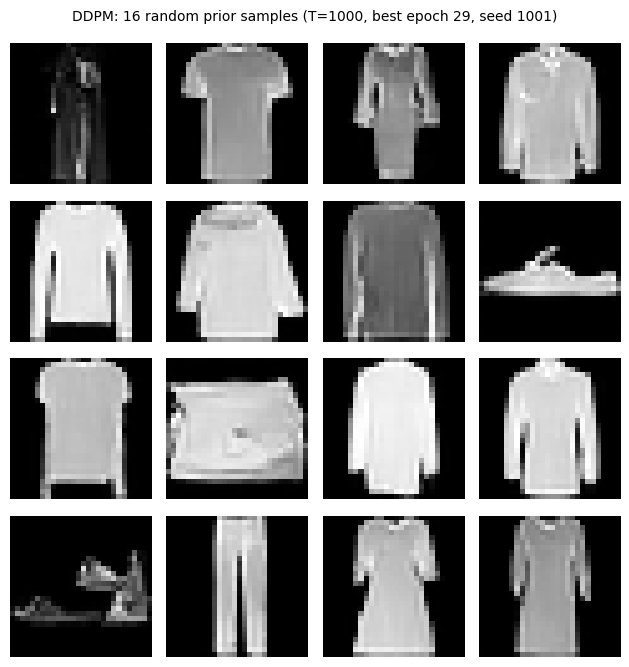

In [15]:
_g = torch.Generator(device=DEVICE).manual_seed(CONFIG["grid_seed"])
_x, _ = ddpm_sample(eval_model, sched, CONFIG["n_grid_samples"], DEVICE, _g, CONFIG["clip_x0_in_sampling"])
samples_16 = to_unit(_x).float().cpu()
assert samples_16.shape == (16, 1, 28, 28) and torch.isfinite(samples_16).all()
atomic_torch_save({"images": samples_16, "seed": CONFIG["grid_seed"], "best_epoch": BEST_EPOCH, "T": CONFIG["T"],
                   "value_range": "[0,1]", "smoke_test": SMOKE_TEST}, PATHS["samples_16"])

fig, axes = plt.subplots(4, 4, figsize=(6.4, 6.8))
for i, ax in enumerate(axes.flat):
    ax.imshow(samples_16[i, 0].numpy(), cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    ax.axis("off")
fig.suptitle(f"DDPM: 16 random prior samples (T={CONFIG['T']}, best epoch {BEST_EPOCH}, seed {CONFIG['grid_seed']})"
             + SMOKE_TAG, fontsize=10)
fig.tight_layout()
atomic_savefig(fig, PATHS["fig_grid"])
plt.show()

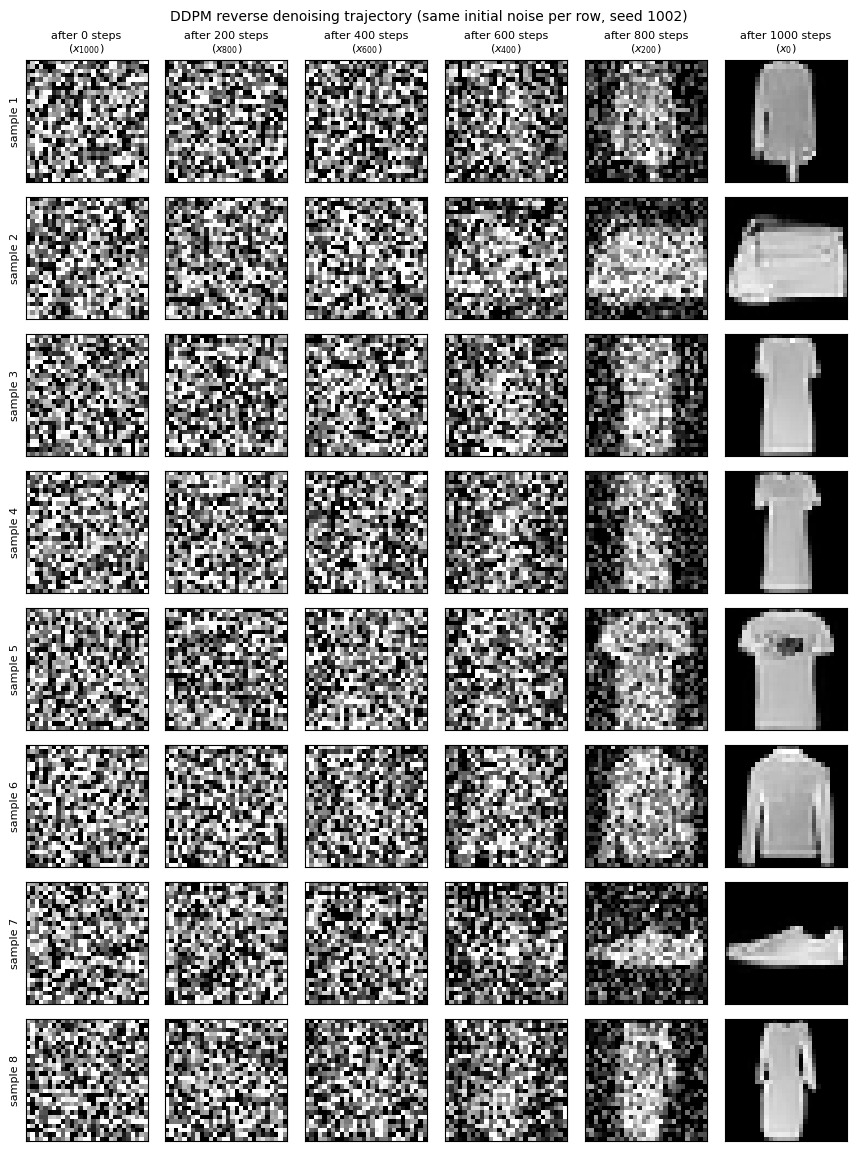

In [16]:
_steps = list(CONFIG["trajectory_steps"])
_g = torch.Generator(device=DEVICE).manual_seed(CONFIG["trajectory_seed"])
_x, _rec = ddpm_sample(eval_model, sched, CONFIG["trajectory_n_samples"], DEVICE, _g,
                       CONFIG["clip_x0_in_sampling"], record_after_steps=_steps)
assert sorted(_rec) == sorted(_steps)
trajectory = torch.stack([to_unit(_rec[s]) for s in _steps], dim=0)
assert trajectory.shape == (len(_steps), CONFIG["trajectory_n_samples"], 1, 28, 28)
assert torch.isfinite(trajectory).all()
assert torch.allclose(trajectory[-1], to_unit(_x).float().cpu())
atomic_torch_save({"images": trajectory, "steps_completed": _steps, "timestep_after_steps": [CONFIG["T"] - s for s in _steps],
                   "seed": CONFIG["trajectory_seed"], "best_epoch": BEST_EPOCH, "T": CONFIG["T"],
                   "layout": "[n_steps, n_samples, 1, 28, 28], value range [0,1]", "smoke_test": SMOKE_TEST},
                  PATHS["trajectory"])

n_s, n_c = CONFIG["trajectory_n_samples"], len(_steps)
fig, axes = plt.subplots(n_s, n_c, figsize=(1.35 * n_c + 0.6, 1.35 * n_s + 0.9))
for r in range(n_s):
    for c, s in enumerate(_steps):
        ax = axes[r, c]
        ax.imshow(trajectory[c, r, 0].numpy(), cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(f"after {s} steps\n($x_{{{CONFIG['T'] - s}}}$)", fontsize=8)
        if c == 0:
            ax.set_ylabel(f"sample {r + 1}", fontsize=8)
fig.suptitle(f"DDPM reverse denoising trajectory (same initial noise per row, seed {CONFIG['trajectory_seed']})"
             + SMOKE_TAG, fontsize=10)
fig.tight_layout()
atomic_savefig(fig, PATHS["fig_trajectory"])
plt.show()

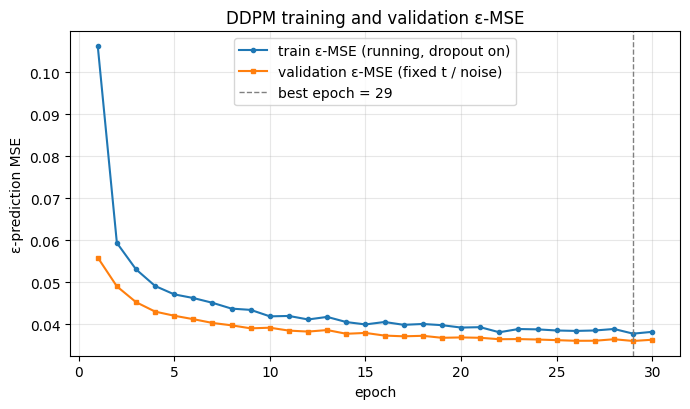

 epoch  train_eps_mse  val_eps_mse  epoch_train_time_sec  epoch_val_time_sec  epoch_time_sec  cumulative_time_sec     lr  improved_best
     1       0.106200     0.055834             38.915155            1.565385       40.480539            40.480539 0.0002           True
     2       0.059323     0.048971             39.691800            1.650185       41.341985            81.822525 0.0002           True
     3       0.053032     0.045216             41.837427            1.692233       43.529661           125.352185 0.0002           True
     4       0.049063     0.042960             40.847913            1.664569       42.512482           167.864668 0.0002           True
     5       0.047064     0.041978             41.207049            1.678534       42.885583           210.750250 0.0002           True
     6       0.046192     0.041156             41.108687            1.682008       42.790695           253.540945 0.0002           True
     7       0.045057     0.040259             4

In [17]:
hist_df = pd.DataFrame(history)
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(hist_df["epoch"], hist_df["train_eps_mse"], marker="o", ms=3, label="train ε-MSE (running, dropout on)")
ax.plot(hist_df["epoch"], hist_df["val_eps_mse"], marker="s", ms=3, label="validation ε-MSE (fixed t / noise)")
ax.axvline(BEST_EPOCH, color="gray", ls="--", lw=1, label=f"best epoch = {BEST_EPOCH}")
ax.set_xlabel("epoch")
ax.set_ylabel("ε-prediction MSE")
ax.set_title("DDPM training and validation ε-MSE" + SMOKE_TAG)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
atomic_savefig(fig, PATHS["fig_loss"])
plt.show()
print(hist_df.to_string(index=False))

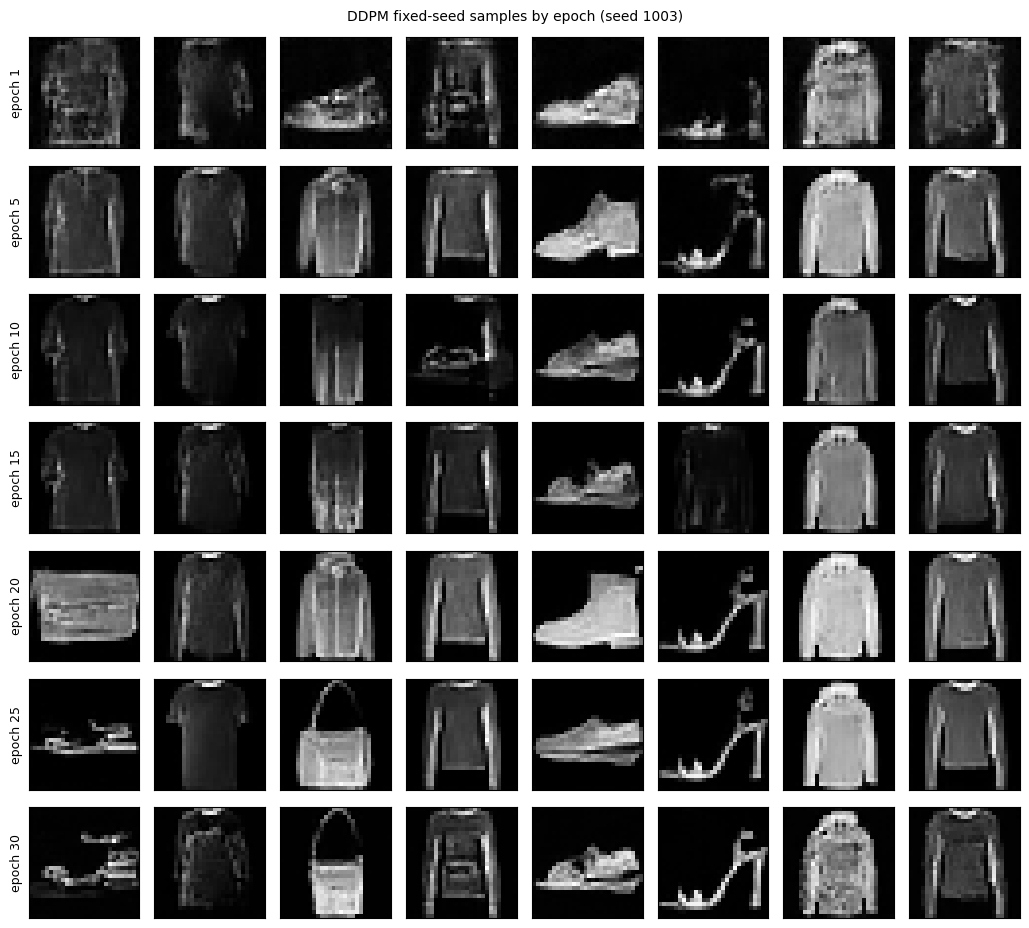

In [18]:
_prog = []
for ep in CONFIG["progression_epochs"]:
    p = os.path.join(PATHS["progression_dir"], f"epoch_{ep:03d}.pt")
    if os.path.isfile(p):
        _prog.append(torch.load(p, map_location="cpu", weights_only=False))
if not _prog:
    print("No progression samples were saved (SAVE_EPOCH_PROGRESSION=False); skipping this optional figure.")
else:
    n_r, n_c = len(_prog), _prog[0]["images"].shape[0]
    fig, axes = plt.subplots(n_r, n_c, figsize=(1.2 * n_c + 0.8, 1.25 * n_r + 0.7), squeeze=False)
    for r, d in enumerate(_prog):
        for c in range(n_c):
            ax = axes[r, c]
            ax.imshow(d["images"][c, 0].numpy(), cmap="gray", vmin=0, vmax=1, interpolation="nearest")
            ax.set_xticks([]); ax.set_yticks([])
            if c == 0:
                ax.set_ylabel(f"epoch {d['epoch']}", fontsize=9)
    fig.suptitle(f"DDPM fixed-seed samples by epoch (seed {CONFIG['progression_seed']})" + SMOKE_TAG, fontsize=10)
    fig.tight_layout()
    atomic_savefig(fig, PATHS["fig_progression"])
    plt.show()

In [19]:
def build_fid_inception():
    block_idx = InceptionV3.BLOCK_INDEX_BY_DIM[CONFIG["fid_dims"]]
    net = InceptionV3([block_idx], resize_input=True, normalize_input=True, use_fid_inception=True)
    return net.to(DEVICE).eval()


@torch.no_grad()
def inception_features(net, images_unit_01, bs):
    assert images_unit_01.ndim == 4 and images_unit_01.shape[1:] == (1, 28, 28)
    assert images_unit_01.min() >= 0 and images_unit_01.max() <= 1, "FID inputs must be canonical [0,1]"
    feats = []
    for i in range(0, images_unit_01.shape[0], bs):
        x = images_unit_01[i:i + bs].to(DEVICE, dtype=torch.float32).repeat(1, 3, 1, 1)  # gray -> RGB
        f = net(x)[0]
        assert f.shape[1:] == (CONFIG["fid_dims"], 1, 1), f.shape
        feats.append(f.squeeze(-1).squeeze(-1).cpu().numpy())
    return np.concatenate(feats, axis=0).astype(np.float64)


def feature_stats(feats):
    feats = np.asarray(feats, dtype=np.float64)
    return feats.mean(axis=0), np.cov(feats, rowvar=False)


def frechet_distance(mu1, sigma1, mu2, sigma2, eps=1e-6):
    mu1, mu2 = np.atleast_1d(mu1).astype(np.float64), np.atleast_1d(mu2).astype(np.float64)
    sigma1, sigma2 = np.atleast_2d(sigma1).astype(np.float64), np.atleast_2d(sigma2).astype(np.float64)
    assert mu1.shape == mu2.shape and sigma1.shape == sigma2.shape
    diff = mu1 - mu2
    info = {"offset_eps_used": 0.0}
    covmean = linalg.sqrtm(sigma1.dot(sigma2))
    if isinstance(covmean, tuple):
        covmean = covmean[0]
    if not np.isfinite(covmean).all():
        offset = np.eye(sigma1.shape[0]) * eps
        covmean = linalg.sqrtm((sigma1 + offset).dot(sigma2 + offset))
        if isinstance(covmean, tuple):
            covmean = covmean[0]
        info["offset_eps_used"] = eps
    if np.iscomplexobj(covmean):
        max_imag = float(np.max(np.abs(covmean.imag)))
        info["max_abs_imag_component"] = max_imag
        if not np.allclose(np.diagonal(covmean).imag, 0, atol=1e-3):
            raise ValueError(f"sqrtm produced a significant imaginary component: {max_imag}")
        covmean = covmean.real
    fid = float(diff.dot(diff) + np.trace(sigma1) + np.trace(sigma2) - 2.0 * np.trace(covmean))
    if not math.isfinite(fid) or fid < -1e-6:
        raise ValueError(f"Invalid FID value: {fid}")
    return fid, info


FID_RESULT = None
if not CONFIG["run_fid"]:
    print("SMOKE TEST: official 7,000-vs-7,000 FID skipped. No FID value is reported.")
else:
    N_FID = CONFIG["fid_n_samples"]
    assert N_FID == 7000 and test_x.shape[0] == 7000

    gen_meta = None
    if os.path.isfile(PATHS["generated_7000"]):
        _old = torch.load(PATHS["generated_7000"], map_location="cpu", weights_only=False)
        if (_old.get("best_checkpoint_sha256") == BEST_CKPT_SHA256 and _old.get("n_samples") == N_FID
                and _old.get("seed") == CONFIG["fid_sample_seed"] and _old.get("T") == CONFIG["T"]):
            gen_meta = _old
            print("Reusing generated_7000.pt (same best checkpoint, seed, and T).")
        else:
            print("Existing generated_7000.pt was produced by a different checkpoint/seed; regenerating for this run.")
        del _old
    if gen_meta is None:
        g = torch.Generator(device=DEVICE).manual_seed(CONFIG["fid_sample_seed"])
        chunks = []
        cuda_sync()
        t0 = time.perf_counter()
        for start in range(0, N_FID, CONFIG["fid_gen_batch_size"]):
            n = min(CONFIG["fid_gen_batch_size"], N_FID - start)
            x, _ = ddpm_sample(eval_model, sched, n, DEVICE, g, CONFIG["clip_x0_in_sampling"])
            chunks.append(to_unit(x).float().cpu())
            print(f"  generated {start + n}/{N_FID}  ({time.perf_counter() - t0:.0f}s)")
        cuda_sync()
        sampling_time = time.perf_counter() - t0
        gen_images = torch.cat(chunks, 0)
        gen_meta = {"images": gen_images, "n_samples": int(gen_images.shape[0]), "seed": CONFIG["fid_sample_seed"],
                    "T": CONFIG["T"], "sampling_wall_clock_sec": sampling_time,
                    "generation_batch_size": CONFIG["fid_gen_batch_size"], "best_epoch": BEST_EPOCH,
                    "best_checkpoint_sha256": BEST_CKPT_SHA256, "value_range": "[0,1]",
                    "device": ENV_INFO.get("gpu_name", str(DEVICE)), "smoke_test": SMOKE_TEST}
        atomic_torch_save(gen_meta, PATHS["generated_7000"])
    gen_images = gen_meta["images"]
    assert gen_images.shape == (N_FID, 1, 28, 28), gen_images.shape
    assert torch.isfinite(gen_images).all() and gen_images.min() >= 0 and gen_images.max() <= 1

    fid_net = build_fid_inception()
    t0 = time.perf_counter()
    feats_real = inception_features(fid_net, test_x, CONFIG["fid_inception_batch_size"])
    feats_gen = inception_features(fid_net, gen_images, CONFIG["fid_inception_batch_size"])
    feat_time = time.perf_counter() - t0
    assert feats_real.shape == (7000, CONFIG["fid_dims"]) and feats_gen.shape == (7000, CONFIG["fid_dims"])
    assert np.isfinite(feats_real).all() and np.isfinite(feats_gen).all()

    mu_r, sig_r = feature_stats(feats_real)
    mu_g, sig_g = feature_stats(feats_gen)
    fid_value, fid_info = frechet_distance(mu_r, sig_r, mu_g, sig_g)
    try:
        fid_crosscheck = float(pytorch_fid_frechet_distance(mu_r, sig_r, mu_g, sig_g))
    except Exception as exc:
        fid_crosscheck = None
        print("pytorch_fid cross-check unavailable:", repr(exc))
    if fid_crosscheck is not None:
        print(f"cross-check (pytorch_fid.calculate_frechet_distance): {fid_crosscheck:.4f}")
        assert abs(fid_crosscheck - fid_value) < 1e-2 * max(1.0, abs(fid_value)), (fid_value, fid_crosscheck)

    atomic_npz_save(PATHS["fid_stats"], mu_real=mu_r, sigma_real=sig_r, mu_gen=mu_g, sigma_gen=sig_g,
                    n_real=np.int64(feats_real.shape[0]), n_gen=np.int64(feats_gen.shape[0]))
    if CONFIG["save_fid_features"]:
        atomic_npz_save(PATHS["fid_features"], features_real=feats_real.astype(np.float32),
                        features_gen=feats_gen.astype(np.float32))

    FID_RESULT = {
        "fid": fid_value,
        "fid_crosscheck_pytorch_fid": fid_crosscheck,
        "n_real": int(feats_real.shape[0]), "n_generated": int(feats_gen.shape[0]),
        "real_set": "project stratified test split (7,000 images, 700/class); official test partition NOT used",
        "real_test_sha256": SPLIT_SHA256["test"],
        "generated_seed": gen_meta["seed"], "generation_T": gen_meta["T"],
        "sampling_wall_clock_sec": gen_meta["sampling_wall_clock_sec"],
        "generation_batch_size": gen_meta["generation_batch_size"],
        "feature_extraction_sec": feat_time,
        "feature_extractor": "pytorch-fid 0.3.0 InceptionV3, use_fid_inception=True, pool3 (2048-d)",
        "preprocessing": "canonical [0,1] grayscale repeated to 3 channels; wrapper bilinear resize to 299x299 "
                         "(align_corners=False) and internal [0,1]->[-1,1] normalization",
        "statistics_dtype": "float64",
        "frechet_info": fid_info,
        "best_epoch": BEST_EPOCH, "best_checkpoint_sha256": BEST_CKPT_SHA256,
        "interpretation": "ImageNet-trained Inception features on upsampled grayscale Fashion-MNIST; use as a relative "
                          "comparison within this project only.",
    }
    atomic_json_save(FID_RESULT, PATHS["fid_json"])
    del fid_net
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    print(f"FID (7,000 test vs 7,000 generated) = {fid_value:.4f}")
    print(f"sampling wall-clock for 7,000 images: {gen_meta['sampling_wall_clock_sec']:.1f}s")

  generated 64/7000  (16s)
  generated 128/7000  (32s)
  generated 192/7000  (48s)
  generated 256/7000  (64s)
  generated 320/7000  (79s)
  generated 384/7000  (95s)
  generated 448/7000  (111s)
  generated 512/7000  (127s)
  generated 576/7000  (142s)
  generated 640/7000  (158s)
  generated 704/7000  (174s)
  generated 768/7000  (190s)
  generated 832/7000  (205s)
  generated 896/7000  (221s)
  generated 960/7000  (237s)
  generated 1024/7000  (253s)
  generated 1088/7000  (268s)
  generated 1152/7000  (284s)
  generated 1216/7000  (300s)
  generated 1280/7000  (316s)
  generated 1344/7000  (333s)
  generated 1408/7000  (348s)
  generated 1472/7000  (364s)
  generated 1536/7000  (380s)
  generated 1600/7000  (396s)
  generated 1664/7000  (412s)
  generated 1728/7000  (427s)
  generated 1792/7000  (443s)
  generated 1856/7000  (459s)
  generated 1920/7000  (475s)
  generated 1984/7000  (491s)
  generated 2048/7000  (506s)
  generated 2112/7000  (525s)
  generated 2176/7000  (541s)
  

100%|██████████| 91.2M/91.2M [00:02<00:00, 33.7MB/s]


cross-check (pytorch_fid.calculate_frechet_distance): 20.7485
FID (7,000 test vs 7,000 generated) = 20.7485
sampling wall-clock for 7,000 images: 1734.5s


In [20]:
LATENCY_RESULT = None
if not CONFIG["run_latency"]:
    print("SMOKE TEST: full reverse-process latency benchmark skipped.")
else:
    B = CONFIG["latency_batch_size"]
    assert B == 64 and sched.T == 1000
    lat_gen = torch.Generator(device=DEVICE).manual_seed(CONFIG["latency_seed"])

    def _full_reverse_process():
        x, _ = ddpm_sample(eval_model, sched, B, DEVICE, lat_gen, CONFIG["clip_x0_in_sampling"])
        return x

    for _ in range(CONFIG["latency_warmup"]):
        cuda_sync()
        _w = _full_reverse_process()
        cuda_sync()
        assert torch.isfinite(_w).all()
    times_ms = []
    for r in range(CONFIG["latency_repeats"]):
        cuda_sync()
        t0 = time.perf_counter()
        _xo = _full_reverse_process()
        cuda_sync()
        times_ms.append((time.perf_counter() - t0) * 1000.0)
        assert _xo.shape == (B, 1, 28, 28) and torch.isfinite(_xo).all()
        print(f"  timed run {r + 1}/{CONFIG['latency_repeats']}: {times_ms[-1]:.1f} ms per batch of {B}")
    arr = np.asarray(times_ms, dtype=np.float64)
    LATENCY_RESULT = {
        "definition": f"complete DDPM ancestral reverse process, all T={sched.T} steps, batch size {B}, "
                      "from x_T ~ N(0,I) to x_0 (not a single U-Net forward call)",
        "batch_size": B, "reverse_steps": sched.T,
        "warmup_runs": CONFIG["latency_warmup"], "timed_runs": CONFIG["latency_repeats"],
        "per_batch_ms_runs": arr.tolist(),
        "per_batch_ms_mean": float(arr.mean()),
        "per_batch_ms_std": float(arr.std(ddof=1)) if len(arr) > 1 else 0.0,
        "per_batch_ms_median": float(np.median(arr)),
        "per_batch_ms_min": float(arr.min()), "per_batch_ms_max": float(arr.max()),
        "per_image_ms_mean": float(arr.mean() / B),
        "per_reverse_step_ms_mean": float(arr.mean() / sched.T),
        "std_ddof": 1,
        "cuda_synchronized": DEVICE.type == "cuda",
        "timer": "time.perf_counter",
        "precision": "float32", "inference_mode": "torch.no_grad, model.eval()",
        "seed": CONFIG["latency_seed"], "best_epoch": BEST_EPOCH,
        "hardware": {k: ENV_INFO.get(k) for k in ["device", "gpu_name", "gpu_compute_capability", "gpu_total_memory_gb",
                                                  "torch", "torch_cuda_version", "cudnn_version", "python", "platform"]},
        "comparability_note": "Full 1,000-step reverse process; do not compare as if it were a one-pass generator call.",
    }
    atomic_json_save(LATENCY_RESULT, PATHS["latency_json"])
    print(f"Latency (batch {B}, full {sched.T}-step reverse process): mean {LATENCY_RESULT['per_batch_ms_mean']:.1f} ms, "
          f"std {LATENCY_RESULT['per_batch_ms_std']:.1f} ms, median {LATENCY_RESULT['per_batch_ms_median']:.1f} ms")

  timed run 1/3: 16195.7 ms per batch of 64
  timed run 2/3: 16044.4 ms per batch of 64
  timed run 3/3: 15715.4 ms per batch of 64
Latency (batch 64, full 1000-step reverse process): mean 15985.2 ms, std 245.6 ms, median 16044.4 ms


In [21]:
NA_REASONS = {
    "test_mse": "N/A - an unconditional DDPM has no input -> reconstruction pathway, so there is no reconstruction to compare.",
    "test_psnr": "N/A - no reconstruction pathway (unconditional DDPM); PSNR requires paired input/reconstruction.",
    "test_ssim": "N/A - no reconstruction pathway (unconditional DDPM); SSIM requires paired input/reconstruction.",
    "latent_interpolation": "N/A - DDPM has no fixed encoder latent space for the project's interpolation experiment "
                            "(x_T is same-dimensional noise, not a learned encoding of an input).",
}
last = history[-1]
metrics = {
    "model_id": CONFIG["model_id"],
    "model_name": CONFIG["model_name"],
    "smoke_test": SMOKE_TEST,
    "results_valid_for_comparison": not SMOKE_TEST,
    "status_note": ("SMOKE TEST ONLY - reduced T and tiny subset; FID and latency not computed; not for reporting."
                    if SMOKE_TEST else "Official full run."),
    "dataset": {"name": "Fashion-MNIST", "pooled_images": 70000, "train": 56000, "validation": 7000, "test": 7000,
                "official_test_partition_retained": False, "split_sha256": SPLIT_SHA256,
                "train_images_used": int(train_x.shape[0]), "val_images_used": int(val_x.shape[0])},
    "n_trainable_params": N_PARAMS,
    "diffusion": {"T": CONFIG["T"], "beta_schedule": "linear", "beta_start": CONFIG["beta_start"],
                  "beta_end": CONFIG["beta_end"], "objective": "epsilon-prediction MSE",
                  "sampler": "ancestral DDPM with posterior mean and posterior variance beta_tilde_t",
                  "clip_x0_in_sampling": CONFIG["clip_x0_in_sampling"]},
    "training": {"epochs_completed": len(history), "batch_size": CONFIG["batch_size"], "lr": CONFIG["lr"],
                 "optimizer": "Adam", "grad_clip_norm": CONFIG["grad_clip_norm"],
                 "final_train_eps_mse": last["train_eps_mse"], "final_val_eps_mse": last["val_eps_mse"],
                 "total_train_val_time_sec": TOTAL_TRAIN_TIME_SEC},
    "checkpoint_selection": {
        "criterion": "lowest deterministic validation epsilon-MSE (fixed timesteps and noise); test data never used",
        "best_epoch": BEST_EPOCH, "best_val_eps_mse": BEST_VAL, "best_checkpoint_sha256": BEST_CKPT_SHA256,
        "note": "Lower validation epsilon-MSE is a training-objective criterion, not a guarantee of lower FID."},
    "fid": FID_RESULT["fid"] if FID_RESULT else None,
    "fid_status": "computed" if FID_RESULT else "not computed (smoke test)",
    "fid_details": FID_RESULT,
    "inference_latency": LATENCY_RESULT,
    "inference_latency_status": "computed" if LATENCY_RESULT else "not computed (smoke test)",
    "test_mse": "N/A", "test_psnr": "N/A", "test_ssim": "N/A", "latent_interpolation": "N/A",
    "not_applicable_reasons": NA_REASONS,
    "environment": ENV_INFO,
    "written_at_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
}
atomic_json_save(metrics, PATHS["metrics_json"])
print(strict_json_dumps({k: metrics[k] for k in ["model_id", "smoke_test", "fid", "fid_status", "n_trainable_params",
                                                  "checkpoint_selection", "test_mse", "latent_interpolation"]}))
if LATENCY_RESULT:
    print(f"latency mean per batch of 64 (full 1000-step reverse process): {LATENCY_RESULT['per_batch_ms_mean']:.1f} ms")

{
  "model_id": "06_ddpm",
  "smoke_test": false,
  "fid": 20.74848332167909,
  "fid_status": "computed",
  "n_trainable_params": 2863393,
  "checkpoint_selection": {
    "criterion": "lowest deterministic validation epsilon-MSE (fixed timesteps and noise); test data never used",
    "best_epoch": 29,
    "best_val_eps_mse": 0.03596466931935302,
    "best_checkpoint_sha256": "1d3b7de6c44b2d725491cc2ae268355edb5a0b7973c5aa5e0f5d016e7182f2e6",
    "note": "Lower validation epsilon-MSE is a training-objective criterion, not a guarantee of lower FID."
  },
  "test_mse": "N/A",
  "latent_interpolation": "N/A"
}
latency mean per batch of 64 (full 1000-step reverse process): 15985.2 ms


In [22]:
failures = []


def check(cond, msg):
    if cond:
        print("  OK  ", msg)
    else:
        print("  FAIL", msg)
        failures.append(msg)


required = ["best_ckpt", "last_ckpt", "history_csv", "metrics_json", "config_json", "split_report", "split_npz",
            "samples_16", "trajectory", "fig_grid", "fig_trajectory", "fig_loss"]
if CONFIG["run_fid"]:
    required += ["generated_7000", "fid_stats", "fid_json"] + (["fid_features"] if CONFIG["save_fid_features"] else [])
if CONFIG["run_latency"]:
    required += ["latency_json"]
if SAVE_EPOCH_PROGRESSION:
    required += ["fig_progression"]

print("[files]")
for key in required:
    p = PATHS[key]
    check(os.path.isfile(p) and os.path.getsize(p) > 0, f"{key}: {os.path.relpath(p, RUN_DIR)}")

print("[strict JSON]")
_json = {}
for key in ["metrics_json", "config_json", "split_report"] + (["fid_json"] if CONFIG["run_fid"] else []) \
        + (["latency_json"] if CONFIG["run_latency"] else []):
    try:
        _json[key] = strict_json_load(PATHS[key])
        check(True, f"{key} parses as strict JSON")
    except Exception as exc:
        check(False, f"{key} strict JSON: {exc!r}")

print("[history]")
h = pd.read_csv(PATHS["history_csv"])
check(len(h) == CONFIG["epochs"], f"history rows {len(h)} == epochs {CONFIG['epochs']}")
check(h["epoch"].tolist() == list(range(1, CONFIG["epochs"] + 1)), "history epochs are 1..N")
check(np.isfinite(h[["train_eps_mse", "val_eps_mse", "epoch_time_sec"]].to_numpy()).all(), "history values finite")

print("[checkpoints]")
for key in ["best_ckpt", "last_ckpt"]:
    ck = torch.load(PATHS[key], map_location="cpu", weights_only=False)
    check(all(k in ck for k in REQUIRED_CKPT_KEYS), f"{key}: required keys present")
    check(all(k in ck["rng_state"] for k in REQUIRED_RNG_KEYS), f"{key}: RNG state (python/numpy/torch/cuda/loader)")
    check(ck["split_sha256"] == SPLIT_SHA256, f"{key}: split hashes match")
    check(all(ck["config"].get(k) == CONFIG.get(k) for k in COMPAT_KEYS), f"{key}: config compatible")
    m_ = build_model(CONFIG)
    try:
        m_.load_state_dict(ck["model_state"], strict=True)
        check(all(torch.isfinite(p).all() for p in m_.parameters()), f"{key}: loads strictly, finite weights")
    except Exception as exc:
        check(False, f"{key}: state_dict load failed {exc!r}")
    check(len(ck["history"]) == ck["epoch"], f"{key}: history length == epoch ({ck['epoch']})")
    if key == "last_ckpt":
        check(ck["epoch"] == CONFIG["epochs"], f"last checkpoint epoch {ck['epoch']} == {CONFIG['epochs']}")
    else:
        check(ck["epoch"] == int(h["val_eps_mse"].idxmin()) + 1, f"best checkpoint epoch {ck['epoch']} == argmin val")
        check(sha256_file(PATHS[key]) == BEST_CKPT_SHA256, "best checkpoint file unchanged since evaluation")
    del ck, m_

print("[samples]")
s16 = torch.load(PATHS["samples_16"], map_location="cpu", weights_only=False)["images"]
check(tuple(s16.shape) == (16, 1, 28, 28) and torch.isfinite(s16).all() and s16.min() >= 0 and s16.max() <= 1,
      f"samples_16 shape {tuple(s16.shape)} in [0,1]")
tr = torch.load(PATHS["trajectory"], map_location="cpu", weights_only=False)
check(tuple(tr["images"].shape) == (len(CONFIG["trajectory_steps"]), CONFIG["trajectory_n_samples"], 1, 28, 28)
      and tr["steps_completed"] == CONFIG["trajectory_steps"], f"trajectory shape {tuple(tr['images'].shape)}")

if CONFIG["run_fid"]:
    print("[FID]")
    g7 = torch.load(PATHS["generated_7000"], map_location="cpu", weights_only=False)
    check(tuple(g7["images"].shape) == (7000, 1, 28, 28) and g7["n_samples"] == 7000, "generated_7000: 7,000 images")
    check(bool(torch.isfinite(g7["images"]).all()) and g7["images"].min() >= 0 and g7["images"].max() <= 1,
          "generated_7000 finite, in [0,1]")
    check(g7["T"] == 1000 and g7["best_checkpoint_sha256"] == BEST_CKPT_SHA256, "generated with T=1000 by best ckpt")
    st = np.load(PATHS["fid_stats"])
    check(st["mu_real"].shape == (2048,) and st["mu_gen"].shape == (2048,), "mu shapes (2048,)")
    check(st["sigma_real"].shape == (2048, 2048) and st["sigma_gen"].shape == (2048, 2048), "sigma shapes (2048,2048)")
    check(int(st["n_real"]) == 7000 and int(st["n_gen"]) == 7000, "FID stats from 7,000 real + 7,000 generated")
    if CONFIG["save_fid_features"]:
        fe = np.load(PATHS["fid_features"])
        check(fe["features_real"].shape == (7000, 2048) and fe["features_gen"].shape == (7000, 2048),
              "feature arrays (7000, 2048)")
    fj = _json.get("metrics_json", {})
    check(isinstance(fj.get("fid"), float) and math.isfinite(fj["fid"]) and fj["fid"] >= 0, f"metrics fid = {fj.get('fid')}")
    check(fj.get("fid_details", {}).get("n_real") == 7000 and fj["fid_details"].get("n_generated") == 7000,
          "metrics: 7,000 vs 7,000")

if CONFIG["run_latency"]:
    print("[latency]")
    lj = _json.get("latency_json", {})
    check(lj.get("batch_size") == 64 and lj.get("reverse_steps") == 1000, "latency: batch 64, full 1000-step reverse")
    check(lj.get("warmup_runs") == 1 and lj.get("timed_runs") == 3 and len(lj.get("per_batch_ms_runs", [])) == 3,
          "latency: 1 warm-up + 3 timed runs")

print("[split]")
sp = np.load(PATHS["split_npz"])
_re = {"train": index_sha256(sp["train_indices"]), "validation": index_sha256(sp["val_indices"]),
       "test": index_sha256(sp["test_indices"])}
check(_re == SPLIT_SHA256, "split_indices.npz hashes == in-memory hashes")
check(_json.get("split_report", {}).get("sha256") == SPLIT_SHA256, "split_report.json hashes match")
check(len(sp["train_indices"]) == 56000 and len(sp["val_indices"]) == 7000 and len(sp["test_indices"]) == 7000,
      "split sizes 56,000 / 7,000 / 7,000")
for k, v in EXPECTED_SPLIT_SHA256.items():
    if v is not None:
        check(_re[k] == v, f"{k} hash == EXPECTED_SPLIT_SHA256")

print("[metric applicability]")
mj = _json.get("metrics_json", {})
check(all(mj.get(k) == "N/A" for k in ["test_mse", "test_psnr", "test_ssim", "latent_interpolation"]),
      "MSE/PSNR/SSIM/interpolation reported as 'N/A' (not 0)")
check(mj.get("smoke_test") == SMOKE_TEST, "metrics smoke flag consistent")

print("[protocol]")
if SMOKE_TEST:
    check(mj.get("fid") is None and mj.get("results_valid_for_comparison") is False,
          "smoke test: no FID reported; marked not valid for comparison")
else:
    try:
        assert_full_run_config(CONFIG)
        check(True, "full-run config: 30 epochs, batch 128, T=1000, 7,000-vs-7,000 FID, batch-64 full-reverse latency")
    except AssertionError as exc:
        check(False, str(exc))

print()
if failures:
    raise AssertionError(f"{len(failures)} verification check(s) failed: {failures}")
print(f"ALL VERIFICATION CHECKS PASSED  ({'SMOKE TEST - not for reporting' if SMOKE_TEST else 'official full run'})")
print("Artifacts in:", RUN_DIR)

[files]
  OK   best_ckpt: checkpoints/best_checkpoint.pt
  OK   last_ckpt: checkpoints/last_checkpoint.pt
  OK   history_csv: metrics/training_history.csv
  OK   metrics_json: metrics/metrics.json
  OK   config_json: metrics/resolved_config.json
  OK   split_report: metrics/split_report.json
  OK   split_npz: metrics/split_indices.npz
  OK   samples_16: samples/samples_16.pt
  OK   trajectory: samples/denoising_trajectory.pt
  OK   fig_grid: figures/samples_grid_4x4.png
  OK   fig_trajectory: figures/denoising_trajectory.png
  OK   fig_loss: figures/loss_curves.png
  OK   generated_7000: samples/generated_7000.pt
  OK   fid_stats: metrics/fid_stats.npz
  OK   fid_json: metrics/fid.json
  OK   fid_features: metrics/fid_features.npz
  OK   latency_json: metrics/latency.json
  OK   fig_progression: figures/sample_progression_by_epoch.png
[strict JSON]
  OK   metrics_json parses as strict JSON
  OK   config_json parses as strict JSON
  OK   split_report parses as strict JSON
  OK   fid_jso